In [1]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import ast
import seaborn as sns
#from adjustText import adjust_text

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x : ast.literal_eval(x) if pd.notna(x) else x)

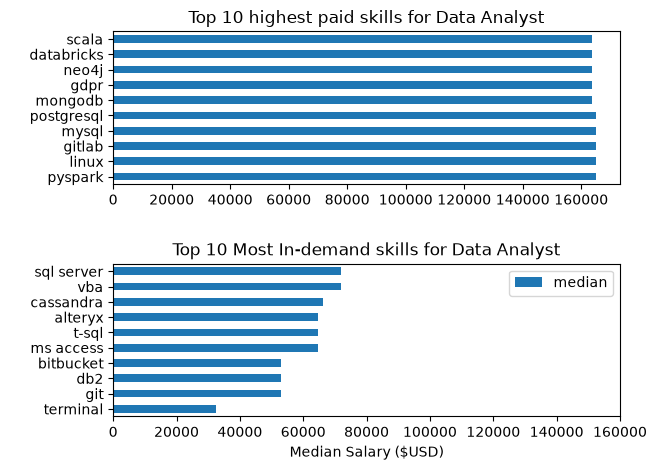

In [3]:
df_DA_ind = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'India')].copy()
df_DA_ind = df_DA_ind.dropna(subset=['salary_year_avg'])
df_DA_ind = df_DA_ind.explode('job_skills')
df_DA_ind_group = df_DA_ind.groupby('job_skills')['salary_year_avg'].agg(['count', 'median'])
df_DA_toppay = df_DA_ind_group.sort_values(by = 'median', ascending=False).head(10)
df_DA_topskills = df_DA_ind_group.sort_values(by='count', ascending = False).sort_values(by='median').head(10)
fig, ax= plt.subplots(2,1)

df_DA_toppay.plot(kind='barh', y='median', ax=ax[0], legend=False)
ax[0].set_title('Top 10 highest paid skills for Data Analyst')
ax[0].set_xlabel(' ')
ax[0].set_ylabel(' ')

df_DA_topskills.plot(kind='barh', y='median', ax=ax[1], legend=False)
ax[1].set_title('Top 10 Most In-demand skills for Data Analyst')
ax[1].set_xlabel('Median Salary ($USD)')
ax[1].set_ylabel(' ')
fig.tight_layout()
plt.legend()
plt.xlim(0,160000)
plt.show()

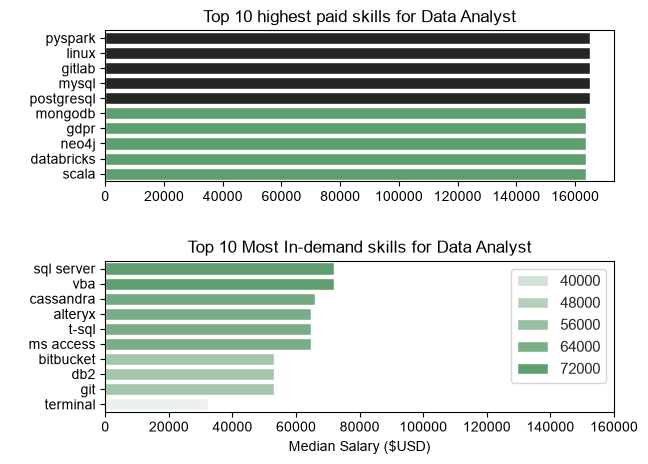

In [16]:
fig, ax= plt.subplots(2,1)

sns.set_theme(style='ticks')

#df_DA_toppay.plot(kind='barh', y='median', ax=ax[0], legend=False)
sns.barplot(data=df_DA_toppay, x='median', y=df_DA_toppay.index, ax=ax[0], hue='median', palette='dark:g_r')
ax[0].legend().remove()
ax[0].set_title('Top 10 highest paid skills for Data Analyst')
ax[0].set_xlabel(' ')
ax[0].set_ylabel(' ')

#df_DA_topskills.plot(kind='barh', y='median', ax=ax[1], legend=False)
sns.barplot(data=df_DA_topskills, x='median', y=df_DA_topskills.index, ax=ax[1], hue='median', palette='light:g')
ax[1].legend().remove()
ax[1].set_title('Top 10 Most In-demand skills for Data Analyst')
ax[1].set_xlabel('Median Salary ($USD)')
ax[1].set_ylabel(' ')
ax[1].invert_yaxis()
fig.tight_layout()
plt.legend()
plt.xlim(0,160000)
plt.show()

Text(0.5, 0, 'Yearly Salary')

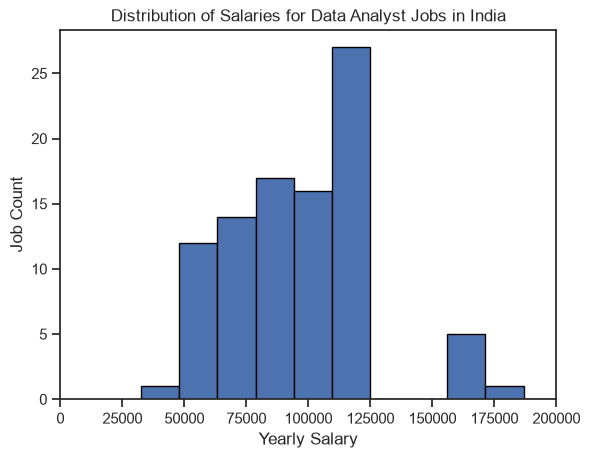

In [18]:
df_DA_ind = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'India')] .copy()
df_DA_ind['salary_year_avg'].plot(kind='hist', bins=40, edgecolor='black')
plt.xlim(0,200000)
plt.title('Distribution of Salaries for Data Analyst Jobs in India')
plt.ylabel('Job Count')
plt.xlabel('Yearly Salary')

Text(0.5, 12.444444444444438, 'Yearly Salary')

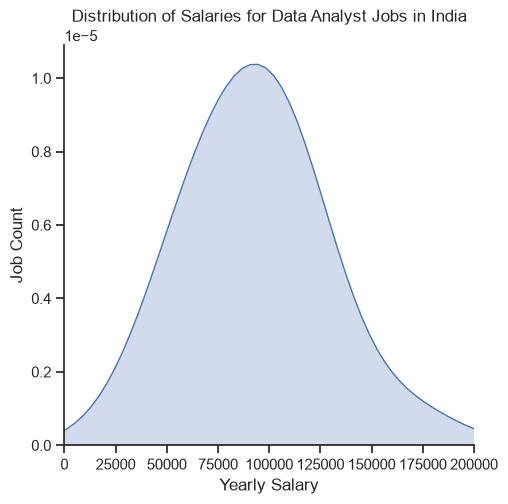

In [22]:
sns.displot(df_DA_ind['salary_year_avg'], kind='kde', fill=True)
plt.xlim(0,200000)
plt.title('Distribution of Salaries for Data Analyst Jobs in India')
plt.ylabel('Job Count')
plt.xlabel('Yearly Salary')